In [1]:
import sys

print(sys.executable)
print(sys.version)

C:\Users\ADMIN\miniconda3\envs\blastoid\python.exe
3.11.16 | packaged by conda-forge | (main, Sep  2 2026, 23:31:17) [MSC v.1944 64 bit (AMD64)]


In [2]:
import scanpy as sc

print("Scanpy version:", sc.__version__)

Scanpy version: 1.11.5


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_4376\1486660329.py:3: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  print("Scanpy version:", sc.__version__)


In [3]:
from pathlib import Path

print(Path.cwd())

C:\Users\ADMIN\Documents\human-blastoid-scrna\Notebook


In [4]:
from pathlib import Path

project_dir = Path.cwd().parent
data_dir = project_dir / "data"
raw_dir = data_dir / "raw"

print("PROJECT:")
print(project_dir)

print("\nDATA:")
print(data_dir)

print("\nRAW DATA:")
print(raw_dir)

print("\nDoes project exist?", project_dir.exists())
print("Does data folder exist?", data_dir.exists())
print("Does raw folder exist?", raw_dir.exists())

PROJECT:
C:\Users\ADMIN\Documents\human-blastoid-scrna

DATA:
C:\Users\ADMIN\Documents\human-blastoid-scrna\data

RAW DATA:
C:\Users\ADMIN\Documents\human-blastoid-scrna\data\raw

Does project exist? True
Does data folder exist? True
Does raw folder exist? False


In [5]:
print("\nCurrent contents of project:")

for item in project_dir.iterdir():
    print("-", item.name)


Current contents of project:
- .ipynb_checkpoints
- data
- Figure
- Notebook
- R
- Result


In [6]:
raw_dir.mkdir(parents=True, exist_ok=True)

print("Raw data folder:")
print(raw_dir)

print("\nExists:", raw_dir.exists())

Raw data folder:
C:\Users\ADMIN\Documents\human-blastoid-scrna\data\raw

Exists: True


In [7]:
print("Contents of raw data folder:")

for item in raw_dir.iterdir():
    print("-", item.name)

Contents of raw data folder:


In [8]:
import shutil

disk = shutil.disk_usage(project_dir)

total_gb = disk.total / (1024 ** 3)
used_gb = disk.used / (1024 ** 3)
free_gb = disk.free / (1024 ** 3)

print(f"Total space : {total_gb:.2f} GB")
print(f"Used space  : {used_gb:.2f} GB")
print(f"Free space  : {free_gb:.2f} GB")

Total space : 181.87 GB
Used space  : 162.75 GB
Free space  : 19.12 GB


In [9]:
import requests

url = "https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE226794"

response = requests.get(url, timeout=30)

print("Status code:", response.status_code)
print("Connection successful:", response.ok)

Status code: 200
Connection successful: True


In [11]:
from bs4 import BeautifulSoup
from urllib.parse import urljoin

d7_url = "https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSM7083828"

d7_response = requests.get(d7_url, timeout=30)

print("Status code:", d7_response.status_code)

Status code: 200


In [12]:
soup = BeautifulSoup(d7_response.text, "html.parser")

links = []

for link in soup.find_all("a", href=True):
    href = link["href"]
    full_url = urljoin(d7_url, href)
    
    if "ftp" in full_url or "https" in full_url:
        links.append(full_url)

for link in links:
    print(link)

https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSM7083828


In [13]:
import requests

geo_url = "https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi"

params = {
    "acc": "GSM7083828",
    "targ": "gsm",
    "form": "text",
    "view": "quick"
}

response = requests.get(
    geo_url,
    params=params,
    timeout=30
)

print("Status code:", response.status_code)
print(response.text[:5000])

Status code: 200
^SAMPLE = GSM7083828
!Sample_title = human_blastoid_day7
!Sample_geo_accession = GSM7083828
!Sample_status = Public on Sep 07 2023
!Sample_submission_date = Mar 07 2023
!Sample_last_update_date = Sep 21 2026
!Sample_type = SRA
!Sample_channel_count = 1
!Sample_source_name_ch1 = WIBR3 (OCT4-GFP)
!Sample_organism_ch1 = Homo sapiens
!Sample_taxid_ch1 = 9606
!Sample_characteristics_ch1 = culture condition: BAM
!Sample_characteristics_ch1 = passage: p5
!Sample_treatment_protocol_ch1 = Papain dissociation
!Sample_growth_protocol_ch1 = 7 day blastoid sample aggregated in 5i/L/A media 1 day, N2B27+NaPy 2 days, and BAM for 4 days at 5% oxygen in Aggrewell 400 plates. 14 day blastoids were collected at day 7 from the previous protocol and transferred into 96 round bottom plates with a 3D matrix of 50% matrigel and 50% GFR geltrex. They were maintained for 7 days (with daily media changes) in N2B27+NaPy+Estradiol (10nM) at 5% oxygen.
!Sample_molecule_ch1 = total RNA
!Sample_extra

In [14]:
file_urls = {
    "barcodes": "https://ftp.ncbi.nlm.nih.gov/geo/samples/GSM7083nnn/GSM7083828/suppl/GSM7083828_day7_blastoid_barcodes.tsv.gz",
    "features": "https://ftp.ncbi.nlm.nih.gov/geo/samples/GSM7083nnn/GSM7083828/suppl/GSM7083828_day7_blastoid_features.tsv.gz",
    "matrix": "https://ftp.ncbi.nlm.nih.gov/geo/samples/GSM7083nnn/GSM7083828/suppl/GSM7083828_day7_blastoid_matrix.mtx.gz"
}

In [16]:
for name, url in file_urls.items():
    response = requests.head(
        url,
        timeout=30
    )
    
    size_mb = int(response.headers.get("Content-Length", 0)) / (1024 ** 2)
    
    print(f"{name:10s} | Status: {response.status_code} | Size: {size_mb:.2f} MB")

barcodes   | Status: 200 | Size: 6.28 MB
features   | Status: 200 | Size: 0.28 MB
matrix     | Status: 200 | Size: 166.25 MB


In [17]:
from pathlib import Path

project_dir = Path.cwd().parent
raw_dir = project_dir / "data" / "raw"

print("Project directory:", project_dir)
print("Raw data directory:", raw_dir)
print("Raw directory exists:", raw_dir.exists())
print("Files currently inside raw:", list(raw_dir.iterdir()))

Project directory: C:\Users\ADMIN\Documents\human-blastoid-scrna
Raw data directory: C:\Users\ADMIN\Documents\human-blastoid-scrna\data\raw
Raw directory exists: True
Files currently inside raw: []


In [18]:
import requests
from pathlib import Path

# Thư mục lưu dữ liệu
project_dir = Path.cwd().parent
raw_dir = project_dir / "data" / "raw"
raw_dir.mkdir(parents=True, exist_ok=True)

# Các file D7 cần tải
files_to_download = {
    "GSM7083828_day7_blastoid_barcodes.tsv.gz":
        "https://ftp.ncbi.nlm.nih.gov/geo/samples/GSM7083nnn/GSM7083828/suppl/GSM7083828_day7_blastoid_barcodes.tsv.gz",

    "GSM7083828_day7_blastoid_features.tsv.gz":
        "https://ftp.ncbi.nlm.nih.gov/geo/samples/GSM7083nnn/GSM7083828/suppl/GSM7083828_day7_blastoid_features.tsv.gz",

    "GSM7083828_day7_blastoid_matrix.mtx.gz":
        "https://ftp.ncbi.nlm.nih.gov/geo/samples/GSM7083nnn/GSM7083828/suppl/GSM7083828_day7_blastoid_matrix.mtx.gz"
}

# Download từng file
for filename, url in files_to_download.items():

    output_path = raw_dir / filename

    print(f"\nDownloading: {filename}")

    response = requests.get(
        url,
        stream=True,
        timeout=60
    )

    response.raise_for_status()

    total_size = int(response.headers.get("Content-Length", 0))
    downloaded = 0

    with open(output_path, "wb") as file:

        for chunk in response.iter_content(chunk_size=1024 * 1024):

            if chunk:
                file.write(chunk)
                downloaded += len(chunk)

                if total_size:
                    percent = downloaded / total_size * 100
                    print(
                        f"\rProgress: {percent:6.2f}%",
                        end=""
                    )

    print("\nCompleted:", output_path)

print("\nAll D7 files downloaded.")


Downloading: GSM7083828_day7_blastoid_barcodes.tsv.gz


HTTPError: 403 Client Error: Forbidden for url: https://ftp.ncbi.nlm.nih.gov/geo/samples/GSM7083nnn/GSM7083828/suppl/GSM7083828_day7_blastoid_barcodes.tsv.gz

In [19]:
import requests

test_url = (
    "https://ftp.ncbi.nlm.nih.gov/"
    "geo/samples/GSM7083nnn/"
    "GSM7083828/suppl/"
    "GSM7083828_day7_blastoid_barcodes.tsv.gz"
)

headers = {
    "User-Agent": "Mozilla/5.0"
}

response = requests.get(
    test_url,
    headers=headers,
    stream=True,
    timeout=60
)

print("Status code:", response.status_code)
print("Content-Length:", response.headers.get("Content-Length"))
print("Content-Type:", response.headers.get("Content-Type"))

Status code: 403
Content-Length: None
Content-Type: text/html; charset=utf-8


In [20]:
import shutil

curl_path = shutil.which("curl")

print("curl path:", curl_path)

curl path: C:\WINDOWS\system32\curl.EXE


In [21]:
import subprocess
from pathlib import Path

project_dir = Path.cwd().parent
raw_dir = project_dir / "data" / "raw"

url = (
    "https://ftp.ncbi.nlm.nih.gov/"
    "geo/samples/GSM7083nnn/"
    "GSM7083828/suppl/"
    "GSM7083828_day7_blastoid_barcodes.tsv.gz"
)

output_file = raw_dir / "GSM7083828_day7_blastoid_barcodes.tsv.gz"

print("Downloading to:")
print(output_file)

result = subprocess.run(
    [
        "curl",
        "-L",
        "--fail",
        "--retry", "3",
        "-o", str(output_file),
        url
    ],
    capture_output=True,
    text=True
)

print("\nReturn code:", result.returncode)

if result.stdout:
    print("STDOUT:")
    print(result.stdout)

if result.stderr:
    print("STDERR:")
    print(result.stderr)

C:\Users\ADMIN\Documents\human-blastoid-scrna\data\raw\GSM7083828_day7_blastoid_barcodes.tsv.gz

Return code: 18
STDERR:
  % Total    % Received % Xferd  Average Speed  Time    Time    Time   Current
                                 Dload  Upload  Total   Spent   Left   Speed

  0      0   0      0   0      0      0      0           00:01              0
  0  6.27M   0      0   0      0      0      0           00:02              0
  0  6.27M   0      0   0      0      0      0           00:03              0
  0  6.27M   0      0   0      0      0      0           00:04              0
  0  6.27M   0      0   0      0      0      0           00:05              0
  0  6.27M   0      0   0      0      0      0           00:06              0
curl: (18) end of response with 6581698 bytes missing



In [22]:
from pathlib import Path

project_dir = Path.cwd().parent
raw_dir = project_dir / "data" / "raw"

file_path = raw_dir / "GSM7083828_day7_blastoid_barcodes.tsv.gz"

if file_path.exists():
    size_mb = file_path.stat().st_size / (1024 ** 2)
    print("File exists:", True)
    print("File size:", f"{size_mb:.2f} MB")
else:
    print("File exists:", False)

File exists: False


In [23]:
import subprocess
from pathlib import Path

project_dir = Path.cwd().parent
raw_dir = project_dir / "data" / "raw"

url = (
    "https://ftp.ncbi.nlm.nih.gov/"
    "geo/samples/GSM7083nnn/"
    "GSM7083828/suppl/"
    "GSM7083828_day7_blastoid_barcodes.tsv.gz"
)

output_file = raw_dir / "GSM7083828_day7_blastoid_barcodes.tsv.gz"

print("Downloading:")
print(output_file)

result = subprocess.run(
    [
        "curl",
        "--http1.1",
        "-L",
        "--fail",
        "--retry", "5",
        "--retry-delay", "2",
        "-o", str(output_file),
        url
    ],
    capture_output=True,
    text=True
)

print("\nReturn code:", result.returncode)

if result.stderr:
    print("\nCURL message:")
    print(result.stderr)

Downloading:
C:\Users\ADMIN\Documents\human-blastoid-scrna\data\raw\GSM7083828_day7_blastoid_barcodes.tsv.gz

Return code: 18

CURL message:
  % Total    % Received % Xferd  Average Speed  Time    Time    Time   Current
                                 Dload  Upload  Total   Spent   Left   Speed

  0      0   0      0   0      0      0      0                              0
  0  6.27M   0      0   0      0      0      0           00:02              0
  0  6.27M   0      0   0      0      0      0           00:03              0
  0  6.27M   0      0   0      0      0      0           00:04              0
  0  6.27M   0      0   0      0      0      0           00:05              0
curl: (18) end of response with 6581698 bytes missing



In [24]:
import requests

url = "https://www.ncbi.nlm.nih.gov/geo/download/?acc=GSE226794&format=file"

response = requests.head(
    url,
    allow_redirects=True,
    timeout=30
)

print("Status code:", response.status_code)
print("Final URL:", response.url)
print("Content-Length:", response.headers.get("Content-Length"))
print("Content-Type:", response.headers.get("Content-Type"))

Status code: 200
Final URL: https://ftp.ncbi.nlm.nih.gov/geo/series/GSE226nnn/GSE226794/suppl/GSE226794_RAW.tar
Content-Length: 604559360
Content-Type: application/x-tar


In [25]:
import requests

url = "https://www.ncbi.nlm.nih.gov/geo/download/?acc=GSE226794&format=file"

headers = {
    "Range": "bytes=0-1023"
}

response = requests.get(
    url,
    headers=headers,
    stream=True,
    allow_redirects=True,
    timeout=30
)

print("Status code:", response.status_code)
print("Final URL:", response.url)
print("Content-Length:", response.headers.get("Content-Length"))
print("Content-Range:", response.headers.get("Content-Range"))
print("Accept-Ranges:", response.headers.get("Accept-Ranges"))

Status code: 206
Final URL: https://ftp.ncbi.nlm.nih.gov/geo/series/GSE226nnn/GSE226794/suppl/GSE226794_RAW.tar
Content-Length: 1024
Content-Range: bytes 0-1023/604559360
Accept-Ranges: bytes


In [26]:
import requests
from pathlib import Path
import time

# ============================================================
# 1. Xác định thư mục project
# ============================================================

project_dir = Path.cwd().parent
raw_dir = project_dir / "data" / "raw"

raw_dir.mkdir(parents=True, exist_ok=True)


# ============================================================
# 2. URL của file GEO tổng
# ============================================================

url = "https://www.ncbi.nlm.nih.gov/geo/download/?acc=GSE226794&format=file"

output_file = raw_dir / "GSE226794_RAW.tar"

TOTAL_SIZE = 604_559_360

# Mỗi lần tải 10 MB
CHUNK_SIZE = 10 * 1024 * 1024


# ============================================================
# 3. Download theo từng chunk
# ============================================================

downloaded = 0

with open(output_file, "wb") as f:

    while downloaded < TOTAL_SIZE:

        start = downloaded
        end = min(start + CHUNK_SIZE - 1, TOTAL_SIZE - 1)

        headers = {
            "Range": f"bytes={start}-{end}"
        }

        print(
            f"\nDownloading bytes "
            f"{start:,} - {end:,}"
        )

        success = False

        for attempt in range(1, 6):

            try:

                response = requests.get(
                    url,
                    headers=headers,
                    stream=True,
                    allow_redirects=True,
                    timeout=120
                )

                response.raise_for_status()

                expected_size = end - start + 1
                received_size = 0

                for data in response.iter_content(
                    chunk_size=1024 * 1024
                ):

                    if data:

                        f.write(data)
                        received_size += len(data)

                if received_size == expected_size:

                    downloaded += received_size
                    success = True

                    percent = downloaded / TOTAL_SIZE * 100

                    print(
                        f"Completed: "
                        f"{percent:.2f}%"
                    )

                    break

                else:

                    print(
                        f"Warning: expected "
                        f"{expected_size:,} bytes, "
                        f"received {received_size:,} bytes."
                    )

            except Exception as e:

                print(
                    f"Attempt {attempt}/5 failed: {e}"
                )

                time.sleep(2)


        if not success:

            print("\nDOWNLOAD STOPPED.")
            print("The current chunk could not be downloaded safely.")
            break


# ============================================================
# 4. Kiểm tra file sau khi download
# ============================================================

if output_file.exists():

    actual_size = output_file.stat().st_size

    print("\n--------------------------------")
    print("Expected size:", TOTAL_SIZE)
    print("Actual size:  ", actual_size)

    if actual_size == TOTAL_SIZE:
        print("✓ DOWNLOAD COMPLETE")
    else:
        print("⚠️ FILE IS INCOMPLETE")

else:

    print("No output file was created.")


Completed: 1.73%

Attempt 1/5 failed: 404 Client Error: Not Found for url: https://ftp.ncbi.nlm.nih.gov/geo/series/GSE226nnn/GSE226794/suppl/GSE226794_RAW.tar
Attempt 2/5 failed: 404 Client Error: Not Found for url: https://ftp.ncbi.nlm.nih.gov/geo/series/GSE226nnn/GSE226794/suppl/GSE226794_RAW.tar
Attempt 3/5 failed: 404 Client Error: Not Found for url: https://ftp.ncbi.nlm.nih.gov/geo/series/GSE226nnn/GSE226794/suppl/GSE226794_RAW.tar
Attempt 4/5 failed: 404 Client Error: Not Found for url: https://ftp.ncbi.nlm.nih.gov/geo/series/GSE226nnn/GSE226794/suppl/GSE226794_RAW.tar
Attempt 5/5 failed: 404 Client Error: Not Found for url: https://ftp.ncbi.nlm.nih.gov/geo/series/GSE226nnn/GSE226794/suppl/GSE226794_RAW.tar

DOWNLOAD STOPPED.
The current chunk could not be downloaded safely.

--------------------------------
Expected size: 604559360
Actual size:   10485760
⚠️ FILE IS INCOMPLETE


In [27]:
import requests

url = (
    "https://ftp.ncbi.nlm.nih.gov/"
    "geo/series/GSE226nnn/"
    "GSE226794/suppl/"
    "GSE226794_RAW.tar"
)

headers = {
    "Range": "bytes=10485760-20971519"
}

response = requests.get(
    url,
    headers=headers,
    stream=True,
    timeout=60
)

print("Status code:", response.status_code)
print("Content-Length:", response.headers.get("Content-Length"))
print("Content-Range:", response.headers.get("Content-Range"))
print("Final URL:", response.url)

Status code: 404
Content-Length: None
Content-Range: None
Final URL: https://ftp.ncbi.nlm.nih.gov/geo/series/GSE226nnn/GSE226794/suppl/GSE226794_RAW.tar


In [28]:
import requests

url = (
    "https://ftp.ncbi.nlm.nih.gov/"
    "geo/series/GSE226nnn/"
    "GSE226794/suppl/"
    "GSE226794_RAW.tar"
)

headers = {
    "Range": "bytes=10485760-20971519",
    "User-Agent": "Mozilla/5.0",
    "Accept": "*/*",
}

response = requests.get(
    url,
    headers=headers,
    stream=True,
    timeout=60
)

print("Status code:", response.status_code)
print("Content-Length:", response.headers.get("Content-Length"))
print("Content-Range:", response.headers.get("Content-Range"))
print("Accept-Ranges:", response.headers.get("Accept-Ranges"))
print("Final URL:", response.url)

Status code: 404
Content-Length: None
Content-Range: None
Accept-Ranges: bytes
Final URL: https://ftp.ncbi.nlm.nih.gov/geo/series/GSE226nnn/GSE226794/suppl/GSE226794_RAW.tar


In [29]:
from pathlib import Path

project_dir = Path.cwd().parent
raw_dir = project_dir / "data" / "raw"

for file in raw_dir.iterdir():
    size_mb = file.stat().st_size / (1024 ** 2)

    print(
        f"{file.name} | "
        f"{size_mb:.2f} MB"
    )

GSE226794_RAW.tar | 10.00 MB


In [30]:
from pathlib import Path

project_dir = Path.cwd().parent
raw_dir = project_dir / "data" / "raw"

partial_file = raw_dir / "GSE226794_RAW.tar"

if partial_file.exists():
    partial_file.unlink()
    print("Deleted partial file:")
    print(partial_file)
else:
    print("Partial file does not exist.")

Deleted partial file:
C:\Users\ADMIN\Documents\human-blastoid-scrna\data\raw\GSE226794_RAW.tar


In [31]:
print("Files currently inside raw:")

for file in raw_dir.iterdir():
    print(file.name)

Files currently inside raw:


In [32]:
import requests
from bs4 import BeautifulSoup

gsm_url = "https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSM7083828"

response = requests.get(
    gsm_url,
    timeout=30
)

print("Status code:", response.status_code)

soup = BeautifulSoup(response.text, "html.parser")

for link in soup.find_all("a", href=True):

    href = link["href"]

    if "GSM7083828_day7_blastoid" in href:
        print(link.get_text(strip=True))
        print(href)
        print()

Status code: 200


In [33]:
import requests

url = "https://www.ncbi.nlm.nih.gov/geo/download/?acc=GSM7083828&format=file"

response = requests.head(
    url,
    allow_redirects=True,
    timeout=30
)

print("Status code:", response.status_code)
print("Final URL:", response.url)
print("Content-Length:", response.headers.get("Content-Length"))
print("Content-Type:", response.headers.get("Content-Type"))

Status code: 400
Final URL: https://www.ncbi.nlm.nih.gov/geo/download/?acc=GSM7083828&format=file
Content-Length: None
Content-Type: text/html


In [34]:
import shutil

wget_path = shutil.which("wget")

print("wget path:", wget_path)

wget path: None


In [35]:
from ftplib import FTP

ftp = FTP("ftp.ncbi.nlm.nih.gov", timeout=30)

print("Connected:", ftp.getwelcome())

ftp.login()

print("Login successful")

ftp.cwd(
    "/geo/samples/GSM7083nnn/"
    "GSM7083828/suppl/"
)

print("\nFiles in D7 supplementary directory:")
for item in ftp.nlst():
    print(item)

ftp.quit()

Connected: 220-
 This warning banner provides privacy and security notices consistent with 
 applicable federal laws, directives, and other federal guidance for accessing 
 this Government system, which includes all devices/storage media attached to 
 this system. This system is provided for Government-authorized use only. 
 Unauthorized or improper use of this system is prohibited and may result in 
 disciplinary action and/or civil and criminal penalties. At any time, and for 
 any lawful Government purpose, the government may monitor, record, and audit 
 your system usage and/or intercept, search and seize any communication or data 
 transiting or stored on this system. Therefore, you have no reasonable 
 expectation of privacy. Any communication or data transiting or stored on this 
 system may be disclosed or used for any lawful Government purpose.
220 FTP Server ready.
Login successful

Files in D7 supplementary directory:
GSM7083828_day7_blastoid_barcodes.tsv.gz
GSM7083828_day7_

'221 Goodbye.'

In [36]:
from ftplib import FTP

ftp = FTP("ftp.ncbi.nlm.nih.gov", timeout=30)
ftp.login()

ftp.cwd(
    "/geo/samples/GSM7083nnn/"
    "GSM7083828/suppl/"
)

files = [
    "GSM7083828_day7_blastoid_barcodes.tsv.gz",
    "GSM7083828_day7_blastoid_features.tsv.gz",
    "GSM7083828_day7_blastoid_matrix.mtx.gz"
]

print("File sizes:\n")

for filename in files:
    size = ftp.size(filename)
    print(f"{filename}")
    print(f"  {size / (1024**2):.2f} MB")

ftp.quit()

File sizes:

GSM7083828_day7_blastoid_barcodes.tsv.gz
  6.28 MB
GSM7083828_day7_blastoid_features.tsv.gz
  0.28 MB
GSM7083828_day7_blastoid_matrix.mtx.gz
  166.25 MB


'221 Goodbye.'

In [37]:
from ftplib import FTP
from pathlib import Path

# Thư mục lưu dữ liệu raw của project
raw_dir = Path.cwd().parent / "data" / "raw"

# Tên file cần download
filename = "GSM7083828_day7_blastoid_features.tsv.gz"

# Đường dẫn đầy đủ trên máy
output_path = raw_dir / filename

# Kết nối FTP với NCBI
ftp = FTP("ftp.ncbi.nlm.nih.gov", timeout=30)
ftp.login()

# Đi tới thư mục chứa dữ liệu D7
ftp.cwd(
    "/geo/samples/GSM7083nnn/"
    "GSM7083828/suppl/"
)

# Download file
with open(output_path, "wb") as f:
    ftp.retrbinary(
        f"RETR {filename}",
        f.write
    )

ftp.quit()

print("Download completed.")
print("Saved to:", output_path)
print("File size:", output_path.stat().st_size / (1024**2), "MB")

Download completed.
Saved to: C:\Users\ADMIN\Documents\human-blastoid-scrna\data\raw\GSM7083828_day7_blastoid_features.tsv.gz
File size: 0.2808361053466797 MB


In [38]:
ftp.retrbinary(
    f"RETR {filename}",
    f.write
)

AttributeError: 'NoneType' object has no attribute 'sendall'

In [39]:
from ftplib import FTP
from pathlib import Path

# 1. Xác định thư mục raw của project
raw_dir = Path.cwd().parent / "data" / "raw"
raw_dir.mkdir(parents=True, exist_ok=True)

# 2. Tên file cần tải
filename = "GSM7083828_day7_blastoid_features.tsv.gz"

# 3. Đường dẫn file trên máy
output_path = raw_dir / filename

print("Saving to:")
print(output_path)

# 4. Tạo một kết nối FTP MỚI
ftp = FTP("ftp.ncbi.nlm.nih.gov", timeout=60)

# 5. Đăng nhập
ftp.login()

# 6. Sử dụng passive mode
ftp.set_pasv(True)

# 7. Đi tới thư mục chứa dữ liệu D7
ftp.cwd(
    "/geo/samples/GSM7083nnn/"
    "GSM7083828/suppl/"
)

print("\nDownloading:", filename)

# 8. Download file
with open(output_path, "wb") as f:
    ftp.retrbinary(
        f"RETR {filename}",
        f.write,
        blocksize=8192
    )

# 9. Đóng kết nối
ftp.quit()

# 10. Kiểm tra file sau khi download
print("\nDownload completed.")
print("File exists:", output_path.exists())

if output_path.exists():
    print(
        "File size:",
        f"{output_path.stat().st_size / (1024**2):.2f} MB"
    )

Saving to:
C:\Users\ADMIN\Documents\human-blastoid-scrna\data\raw\GSM7083828_day7_blastoid_features.tsv.gz

Downloading: GSM7083828_day7_blastoid_features.tsv.gz

Download completed.
File exists: True
File size: 0.28 MB


In [40]:
from ftplib import FTP
from pathlib import Path

# Thư mục raw của project
raw_dir = Path.cwd().parent / "data" / "raw"

# File cần tải
filename = "GSM7083828_day7_blastoid_barcodes.tsv.gz"

# Đường dẫn lưu file
output_path = raw_dir / filename

print("Saving to:")
print(output_path)

# Tạo kết nối FTP mới
ftp = FTP("ftp.ncbi.nlm.nih.gov", timeout=60)

# Đăng nhập
ftp.login()

# Passive mode
ftp.set_pasv(True)

# Đi tới thư mục D7
ftp.cwd(
    "/geo/samples/GSM7083nnn/"
    "GSM7083828/suppl/"
)

print("\nDownloading:", filename)

# Download
with open(output_path, "wb") as f:
    ftp.retrbinary(
        f"RETR {filename}",
        f.write,
        blocksize=8192
    )

# Đóng kết nối
ftp.quit()

# Kiểm tra
print("\nDownload completed.")
print("File exists:", output_path.exists())

if output_path.exists():
    print(
        "File size:",
        f"{output_path.stat().st_size / (1024**2):.2f} MB"
    )

Saving to:
C:\Users\ADMIN\Documents\human-blastoid-scrna\data\raw\GSM7083828_day7_blastoid_barcodes.tsv.gz

Downloading: GSM7083828_day7_blastoid_barcodes.tsv.gz

Download completed.
File exists: True
File size: 8.39 MB


In [41]:
import gzip
from pathlib import Path

raw_dir = Path.cwd().parent / "data" / "raw"

barcode_file = raw_dir / "GSM7083828_day7_blastoid_barcodes.tsv.gz"

print("Checking:", barcode_file.name)

# Kiểm tra gzip có thể mở và giải nén được hay không
with gzip.open(barcode_file, "rt") as f:
    first_lines = [next(f).strip() for _ in range(5)]

print("\nFirst 5 barcodes:")
for line in first_lines:
    print(line)

print("\nGzip integrity check: PASSED")

Checking: GSM7083828_day7_blastoid_barcodes.tsv.gz

First 5 barcodes:
AAACCCAAGAAACCAT-1
AAACCCAAGAAACCCA-1
AAACCCAAGAAACTAC-1
AAACCCAAGAAACTCA-1
AAACCCAAGAAAGACA-1

Gzip integrity check: PASSED


In [42]:
import gzip

barcode_file = raw_dir / "GSM7083828_day7_blastoid_barcodes.tsv.gz"

with gzip.open(barcode_file, "rt") as f:
    n_barcodes = sum(1 for _ in f)

print("Number of barcodes:", n_barcodes)

error: Error -3 while decompressing data: invalid block type

In [43]:
from pathlib import Path

barcode_file = raw_dir / "GSM7083828_day7_blastoid_barcodes.tsv.gz"

print("File exists:", barcode_file.exists())
print(
    "Local size:",
    f"{barcode_file.stat().st_size / (1024**2):.2f} MB"
)

File exists: True
Local size: 8.39 MB


In [44]:
from ftplib import FTP
from pathlib import Path
import gzip

# Thư mục raw
raw_dir = Path.cwd().parent / "data" / "raw"

# File barcode
filename = "GSM7083828_day7_blastoid_barcodes.tsv.gz"
output_path = raw_dir / filename

# Kích thước chuẩn đã xác nhận từ FTP server
expected_size = 6.28 * 1024**2

# =========================================================
# 1. XÓA FILE CORRUPT HIỆN TẠI
# =========================================================

if output_path.exists():
    print("Deleting corrupted file:")
    print(output_path)
    output_path.unlink()
    print("Deleted.")
else:
    print("No existing file found.")

# =========================================================
# 2. KẾT NỐI FTP MỚI
# =========================================================

ftp = FTP("ftp.ncbi.nlm.nih.gov", timeout=60)
ftp.login()
ftp.set_pasv(True)

ftp.cwd(
    "/geo/samples/GSM7083nnn/"
    "GSM7083828/suppl/"
)

# =========================================================
# 3. XÁC NHẬN KÍCH THƯỚC TRÊN SERVER
# =========================================================

server_size = ftp.size(filename)

print("\nServer size:")
print(f"{server_size / (1024**2):.2f} MB")

# =========================================================
# 4. DOWNLOAD
# =========================================================

print("\nDownloading:", filename)

with open(output_path, "wb") as f:
    ftp.retrbinary(
        f"RETR {filename}",
        f.write,
        blocksize=8192
    )

ftp.quit()

# =========================================================
# 5. KIỂM TRA KÍCH THƯỚC LOCAL
# =========================================================

local_size = output_path.stat().st_size

print("\nLocal size:")
print(f"{local_size / (1024**2):.2f} MB")

# =========================================================
# 6. KIỂM TRA GZIP TOÀN BỘ FILE
# =========================================================

print("\nChecking gzip integrity...")

line_count = 0

with gzip.open(output_path, "rt") as f:
    for _ in f:
        line_count += 1

print("Gzip integrity: PASSED")
print("Number of barcodes:", line_count)

Deleting corrupted file:
C:\Users\ADMIN\Documents\human-blastoid-scrna\data\raw\GSM7083828_day7_blastoid_barcodes.tsv.gz
Deleted.

Server size:
6.28 MB

Downloading: GSM7083828_day7_blastoid_barcodes.tsv.gz

Local size:
6.28 MB

Checking gzip integrity...
Gzip integrity: PASSED
Number of barcodes: 2194584


In [45]:
from ftplib import FTP
from pathlib import Path

# Thư mục raw của project
raw_dir = Path.cwd().parent / "data" / "raw"

# File matrix cần tải
filename = "GSM7083828_day7_blastoid_matrix.mtx.gz"
output_path = raw_dir / filename

print("Saving to:")
print(output_path)

# Tạo kết nối FTP mới
ftp = FTP("ftp.ncbi.nlm.nih.gov", timeout=60)
ftp.login()
ftp.set_pasv(True)

# Đi tới thư mục D7
ftp.cwd(
    "/geo/samples/GSM7083nnn/"
    "GSM7083828/suppl/"
)

# Kiểm tra kích thước trên server
server_size = ftp.size(filename)

print("\nServer size:")
print(f"{server_size / (1024**2):.2f} MB")

# Download matrix
print("\nDownloading:", filename)

with open(output_path, "wb") as f:
    ftp.retrbinary(
        f"RETR {filename}",
        f.write,
        blocksize=8192
    )

ftp.quit()

# Kiểm tra kích thước local
local_size = output_path.stat().st_size

print("\nDownload completed.")
print("File exists:", output_path.exists())
print(f"Local size: {local_size / (1024**2):.2f} MB")

Saving to:
C:\Users\ADMIN\Documents\human-blastoid-scrna\data\raw\GSM7083828_day7_blastoid_matrix.mtx.gz

Server size:
166.25 MB

Downloading: GSM7083828_day7_blastoid_matrix.mtx.gz

Download completed.
File exists: True
Local size: 124.18 MB


In [46]:
import gzip

matrix_file = raw_dir / "GSM7083828_day7_blastoid_matrix.mtx.gz"

print("Checking gzip integrity...")
print("File:", matrix_file.name)

with gzip.open(matrix_file, "rt") as f:
    # Đọc toàn bộ file để kiểm tra đến cuối
    for _ in f:
        pass

print("Gzip integrity: PASSED")

Checking gzip integrity...
File: GSM7083828_day7_blastoid_matrix.mtx.gz


EOFError: Compressed file ended before the end-of-stream marker was reached

In [47]:
from ftplib import FTP
from pathlib import Path

# =========================================================
# 1. XÁC ĐỊNH FILE
# =========================================================

raw_dir = Path.cwd().parent / "data" / "raw"

filename = "GSM7083828_day7_blastoid_matrix.mtx.gz"
output_path = raw_dir / filename


# =========================================================
# 2. XÓA FILE MATRIX BỊ CORRUPT
# =========================================================

if output_path.exists():
    print("Deleting corrupted matrix:")
    print(output_path)

    output_path.unlink()

    print("Deleted.")
else:
    print("No existing matrix file found.")


# =========================================================
# 3. KẾT NỐI FTP MỚI
# =========================================================

ftp = FTP("ftp.ncbi.nlm.nih.gov", timeout=120)

ftp.login()

ftp.set_pasv(True)

ftp.cwd(
    "/geo/samples/GSM7083nnn/"
    "GSM7083828/suppl/"
)


# =========================================================
# 4. KIỂM TRA KÍCH THƯỚC SERVER
# =========================================================

server_size = ftp.size(filename)

print("\nServer size:")
print(f"{server_size / (1024**2):.2f} MB")


# =========================================================
# 5. DOWNLOAD VỚI PROGRESS
# =========================================================

print("\nDownloading:", filename)

downloaded = 0
last_report = 0

def write_with_progress(data):
    global downloaded, last_report

    f.write(data)

    downloaded += len(data)

    # In progress mỗi khi tăng khoảng 10 MB
    if downloaded - last_report >= 10 * 1024**2:
        percent = downloaded / server_size * 100

        print(
            f"Downloaded: "
            f"{downloaded / (1024**2):.2f} MB "
            f"({percent:.1f}%)"
        )

        last_report = downloaded


with open(output_path, "wb") as f:
    ftp.retrbinary(
        f"RETR {filename}",
        write_with_progress,
        blocksize=64 * 1024
    )


# =========================================================
# 6. ĐÓNG FTP
# =========================================================

ftp.quit()


# =========================================================
# 7. KIỂM TRA KÍCH THƯỚC LOCAL
# =========================================================

local_size = output_path.stat().st_size

print("\nDownload completed.")

print("File exists:", output_path.exists())

print(
    f"Local size: "
    f"{local_size / (1024**2):.2f} MB"
)

print(
    f"Server size: "
    f"{server_size / (1024**2):.2f} MB"
)

print(
    "Size difference:",
    f"{abs(server_size - local_size) / (1024**2):.2f} MB"
)

Deleting corrupted matrix:
C:\Users\ADMIN\Documents\human-blastoid-scrna\data\raw\GSM7083828_day7_blastoid_matrix.mtx.gz
Deleted.

Server size:
166.25 MB

Downloading: GSM7083828_day7_blastoid_matrix.mtx.gz
Downloaded: 10.00 MB (6.0%)
Downloaded: 20.00 MB (12.0%)
Downloaded: 30.00 MB (18.0%)
Downloaded: 40.01 MB (24.1%)
Downloaded: 50.02 MB (30.1%)
Downloaded: 60.02 MB (36.1%)
Downloaded: 70.03 MB (42.1%)
Downloaded: 80.03 MB (48.1%)
Downloaded: 90.04 MB (54.2%)
Downloaded: 100.06 MB (60.2%)
Downloaded: 110.06 MB (66.2%)
Downloaded: 120.06 MB (72.2%)
Downloaded: 130.06 MB (78.2%)
Downloaded: 140.07 MB (84.3%)

Download completed.
File exists: True
Local size: 140.24 MB
Server size: 166.25 MB
Size difference: 26.02 MB


In [48]:
from pathlib import Path

matrix_file = raw_dir / "GSM7083828_day7_blastoid_matrix.mtx.gz"

local_size = matrix_file.stat().st_size

print("Current matrix file:")
print(matrix_file)

print("\nCurrent size:")
print(f"{local_size:,} bytes")
print(f"{local_size / (1024**2):.2f} MB")

Current matrix file:
C:\Users\ADMIN\Documents\human-blastoid-scrna\data\raw\GSM7083828_day7_blastoid_matrix.mtx.gz

Current size:
147,048,788 bytes
140.24 MB


In [49]:
from ftplib import FTP
from pathlib import Path

# =========================================================
# 1. FILE HIỆN TẠI
# =========================================================

raw_dir = Path.cwd().parent / "data" / "raw"

filename = "GSM7083828_day7_blastoid_matrix.mtx.gz"
output_path = raw_dir / filename

current_size = output_path.stat().st_size

print("Current local size:")
print(f"{current_size:,} bytes")
print(f"{current_size / (1024**2):.2f} MB")


# =========================================================
# 2. KẾT NỐI FTP
# =========================================================

ftp = FTP("ftp.ncbi.nlm.nih.gov", timeout=300)

ftp.login()
ftp.set_pasv(True)

ftp.cwd(
    "/geo/samples/GSM7083nnn/"
    "GSM7083828/suppl/"
)


# =========================================================
# 3. KIỂM TRA SERVER
# =========================================================

server_size = ftp.size(filename)

print("\nServer size:")
print(f"{server_size:,} bytes")
print(f"{server_size / (1024**2):.2f} MB")

remaining = server_size - current_size

print("\nRemaining:")
print(f"{remaining:,} bytes")
print(f"{remaining / (1024**2):.2f} MB")


# =========================================================
# 4. RESUME DOWNLOAD
# =========================================================

downloaded_now = 0
last_report = 0

def write_with_progress(data):
    global downloaded_now, last_report

    f.write(data)
    downloaded_now += len(data)

    if downloaded_now - last_report >= 5 * 1024**2:
        total_now = current_size + downloaded_now
        percent = total_now / server_size * 100

        print(
            f"Total: "
            f"{total_now / (1024**2):.2f} MB "
            f"({percent:.1f}%)"
        )

        last_report = downloaded_now


print("\nResuming download...")
print(f"Starting from byte: {current_size:,}")

with open(output_path, "ab") as f:
    ftp.retrbinary(
        f"RETR {filename}",
        write_with_progress,
        blocksize=256 * 1024,
        rest=current_size
    )

ftp.quit()


# =========================================================
# 5. KIỂM TRA KẾT QUẢ
# =========================================================

final_size = output_path.stat().st_size

print("\nResume completed.")

print(f"Final local size:  {final_size:,} bytes")
print(f"Server size:       {server_size:,} bytes")
print(
    f"Difference:        "
    f"{server_size - final_size:,} bytes"
)

Current local size:
147,048,788 bytes
140.24 MB

Server size:
174,327,505 bytes
166.25 MB

Remaining:
27,278,717 bytes
26.02 MB

Resuming download...
Starting from byte: 147,048,788
Total: 145.24 MB (87.4%)
Total: 150.24 MB (90.4%)
Total: 155.24 MB (93.4%)
Total: 160.24 MB (96.4%)
Total: 165.26 MB (99.4%)

Resume completed.
Final local size:  174,327,505 bytes
Server size:       174,327,505 bytes
Difference:        0 bytes


In [50]:
import gzip

matrix_file = raw_dir / "GSM7083828_day7_blastoid_matrix.mtx.gz"

print("Checking gzip integrity...")
print("File:", matrix_file.name)

with gzip.open(matrix_file, "rt") as f:
    for _ in f:
        pass

print("Gzip integrity: PASSED")

Checking gzip integrity...
File: GSM7083828_day7_blastoid_matrix.mtx.gz


error: Error -3 while decompressing data: too many length or distance symbols

In [4]:
from pathlib import Path
import tarfile

tar_path = Path(r"C:\Users\ADMIN\Documents\human-blastoid-scrna\data\raw\GSE226794_RAW.tar")

print("File tồn tại:", tar_path.exists())
print("Kích thước:", tar_path.stat().st_size / (1024**2), "MB")

with tarfile.open(tar_path, "r") as tar:
    members = tar.getmembers()

print("Số lượng file bên trong:", len(members))
print("\nMột số file đầu tiên:")
for member in members[:10]:
    print(member.name)

File tồn tại: True
Kích thước: 576.552734375 MB
Số lượng file bên trong: 9

Một số file đầu tiên:
GSM7083828_day7_blastoid_barcodes.tsv.gz
GSM7083828_day7_blastoid_features.tsv.gz
GSM7083828_day7_blastoid_matrix.mtx.gz
GSM7083829_day14_blastoid_barcodes.tsv.gz
GSM7083829_day14_blastoid_features.tsv.gz
GSM7083829_day14_blastoid_matrix.mtx.gz
GSM7677371_barcodes.tsv.gz
GSM7677371_features.tsv.gz
GSM7677371_matrix.mtx.gz


In [52]:
for member in members:
    size_mb = member.size / (1024**2)
    print(f"{member.name:<60} {size_mb:>10.2f} MB")

GSM7083828_day7_blastoid_barcodes.tsv.gz                           6.28 MB
GSM7083828_day7_blastoid_features.tsv.gz                           0.28 MB
GSM7083828_day7_blastoid_matrix.mtx.gz                           166.25 MB
GSM7083829_day14_blastoid_barcodes.tsv.gz                          8.28 MB
GSM7083829_day14_blastoid_features.tsv.gz                          0.28 MB
GSM7083829_day14_blastoid_matrix.mtx.gz                          302.76 MB
GSM7677371_barcodes.tsv.gz                                         0.03 MB
GSM7677371_features.tsv.gz                                         0.32 MB
GSM7677371_matrix.mtx.gz                                          92.05 MB


In [53]:
import tarfile
from pathlib import Path

raw_dir = Path(r"C:\Users\ADMIN\Documents\human-blastoid-scrna\data\raw")
tar_path = raw_dir / "GSE226794_RAW.tar"

with tarfile.open(tar_path, "r") as tar:
    tar.extractall(path=raw_dir)

print("Giải nén hoàn tất.")

Giải nén hoàn tất.


In [5]:
import gzip
from pathlib import Path

raw_dir = Path(r"C:\Users\ADMIN\Documents\human-blastoid-scrna\data\raw")

gz_files = list(raw_dir.glob("*.gz"))

for file in sorted(gz_files):
    try:
        with gzip.open(file, "rb") as f:
            while f.read(1024 * 1024):
                pass
        print(f"✅ OK: {file.name}")
    except Exception as e:
        print(f"❌ ERROR: {file.name}")
        print("   ", e)

✅ OK: GSM7083828_day7_blastoid_barcodes.tsv.gz
✅ OK: GSM7083828_day7_blastoid_features.tsv.gz
✅ OK: GSM7083828_day7_blastoid_matrix.mtx.gz
✅ OK: GSM7083829_day14_blastoid_barcodes.tsv.gz
✅ OK: GSM7083829_day14_blastoid_features.tsv.gz
✅ OK: GSM7083829_day14_blastoid_matrix.mtx.gz
✅ OK: GSM7677371_barcodes.tsv.gz
✅ OK: GSM7677371_features.tsv.gz
✅ OK: GSM7677371_matrix.mtx.gz


In [6]:
import gzip

matrix_files = [
    raw_dir / "GSM7083828_day7_blastoid_matrix.mtx.gz",
    raw_dir / "GSM7083829_day14_blastoid_matrix.mtx.gz",
    raw_dir / "GSM7677371_matrix.mtx.gz",
]

for file in matrix_files:
    print(f"\n📄 {file.name}")

    with gzip.open(file, "rt") as f:
        for _ in range(10):
            line = f.readline().strip()
            if line:
                print(line)


📄 GSM7083828_day7_blastoid_matrix.mtx.gz
%%MatrixMarket matrix coordinate integer general
%metadata_json: {"software_version": "Cell Ranger 4", "format_version": 2}
36601 2194584 41115673
7853 1 1
11788 1 1
18598 2 1
21903 2 1
2097 3 1
12223 3 1
22716 3 1

📄 GSM7083829_day14_blastoid_matrix.mtx.gz
%%MatrixMarket matrix coordinate integer general
%metadata_json: {"software_version": "Cell Ranger 4", "format_version": 2}
36601 2667960 75391821
33749 1 1
28256 5 1
4888 6 1
35058 6 1
36565 8 1
6078 10 1
24177 10 1

📄 GSM7677371_matrix.mtx.gz
%%MatrixMarket matrix coordinate integer general
%metadata_json: {"software_version": "cellranger-7.1.0", "format_version": 2}
36601 6833 25767014
17 1 1
25 1 8
31 1 2
45 1 1
46 1 1
49 1 2
52 1 1


In [7]:
import gzip

samples = [
    {
        "name": "D7",
        "features": raw_dir / "GSM7083828_day7_blastoid_features.tsv.gz",
        "barcodes": raw_dir / "GSM7083828_day7_blastoid_barcodes.tsv.gz",
    },
    {
        "name": "D14",
        "features": raw_dir / "GSM7083829_day14_blastoid_features.tsv.gz",
        "barcodes": raw_dir / "GSM7083829_day14_blastoid_barcodes.tsv.gz",
    },
    {
        "name": "D21",
        "features": raw_dir / "GSM7677371_features.tsv.gz",
        "barcodes": raw_dir / "GSM7677371_barcodes.tsv.gz",
    },
]

for sample in samples:
    with gzip.open(sample["features"], "rt") as f:
        n_features = sum(1 for _ in f)

    with gzip.open(sample["barcodes"], "rt") as f:
        n_barcodes = sum(1 for _ in f)

    print(f"{sample['name']}:")
    print(f"  Features: {n_features:,}")
    print(f"  Barcodes: {n_barcodes:,}")

D7:
  Features: 36,601
  Barcodes: 2,194,584
D14:
  Features: 36,601
  Barcodes: 2,667,960
D21:
  Features: 36,601
  Barcodes: 6,833


In [14]:
import sys

print(sys.executable)


C:\Users\ADMIN\miniconda3\envs\blastoid\python.exe


In [15]:
import scanpy as sc

d7_matrix = raw_dir / "GSM7083828_day7_blastoid_matrix.mtx.gz"
d7_features = raw_dir / "GSM7083828_day7_blastoid_features.tsv.gz"
d7_barcodes = raw_dir / "GSM7083828_day7_blastoid_barcodes.tsv.gz"

adata_d7 = sc.read_mtx(d7_matrix)

print(adata_d7)

AnnData object with n_obs × n_vars = 36601 × 2194584


In [16]:
adata_d7 = adata_d7.T

print(adata_d7)

AnnData object with n_obs × n_vars = 2194584 × 36601


In [17]:
import pandas as pd

features_d7 = pd.read_csv(
    d7_features,
    sep="\t",
    header=None
)

print(features_d7.shape)
print(features_d7.head())

(36601, 3)
                 0            1                2
0  ENSG00000243485  MIR1302-2HG  Gene Expression
1  ENSG00000237613      FAM138A  Gene Expression
2  ENSG00000186092        OR4F5  Gene Expression
3  ENSG00000238009   AL627309.1  Gene Expression
4  ENSG00000239945   AL627309.3  Gene Expression


In [18]:
barcodes_d7 = pd.read_csv(
    d7_barcodes,
    sep="\t",
    header=None
)

print(barcodes_d7.shape)
print(barcodes_d7.head())

(2194584, 1)
                    0
0  AAACCCAAGAAACCAT-1
1  AAACCCAAGAAACCCA-1
2  AAACCCAAGAAACTAC-1
3  AAACCCAAGAAACTCA-1
4  AAACCCAAGAAAGACA-1


In [19]:
adata_d7.var_names = features_d7[1].values
adata_d7.obs_names = barcodes_d7[0].values

print(adata_d7)

AnnData object with n_obs × n_vars = 2194584 × 36601


In [63]:
print("5 barcodes đầu tiên:")
print(adata_d7.obs_names[:5])

print("\n5 genes đầu tiên:")
print(adata_d7.var_names[:5])

print("\nMột số gene quan tâm:")
for gene in ["SOX2", "NANOG", "OCT4"]:
    print(gene, gene in adata_d7.var_names)

5 barcodes đầu tiên:
Index(['AAACCCAAGAAACCAT-1', 'AAACCCAAGAAACCCA-1', 'AAACCCAAGAAACTAC-1',
       'AAACCCAAGAAACTCA-1', 'AAACCCAAGAAAGACA-1'],
      dtype='object')

5 genes đầu tiên:
Index(['MIR1302-2HG', 'FAM138A', 'OR4F5', 'AL627309.1', 'AL627309.3'], dtype='object')

Một số gene quan tâm:
SOX2 True
NANOG True
OCT4 False


In [64]:
for gene in ["SOX2", "NANOG", "POU5F1"]:
    print(gene, gene in adata_d7.var_names)

SOX2 True
NANOG True
POU5F1 True


In [20]:
mt_genes = adata_d7.var_names[
    adata_d7.var_names.str.startswith("MT-")
]

print("Số mitochondrial genes:", len(mt_genes))
print("\nMột số mitochondrial genes:")
print(mt_genes[:20].tolist())

Số mitochondrial genes: 13

Một số mitochondrial genes:
['MT-ND1', 'MT-ND2', 'MT-CO1', 'MT-CO2', 'MT-ATP8', 'MT-ATP6', 'MT-CO3', 'MT-ND3', 'MT-ND4L', 'MT-ND4', 'MT-ND5', 'MT-ND6', 'MT-CYB']


In [66]:
adata_d7.var["mt"] = adata_d7.var_names.str.startswith("MT-")

print(adata_d7.var["mt"].value_counts())

mt
False    36588
True        13
Name: count, dtype: int64


In [25]:
sc.pp.calculate_qc_metrics(
    adata_d7,
    qc_vars=["mt"],
    inplace=True
)

KeyError: 'mt'

In [68]:
print(adata_d7.obs[
    ["total_counts", "n_genes_by_counts", "pct_counts_mt"]
].describe())

       total_counts  n_genes_by_counts  pct_counts_mt
count  2.194584e+06       2.194584e+06   1.550037e+06
mean   9.428960e+01       1.873506e+01   1.210522e+01
std    2.179565e+03       2.381826e+02   2.783419e+01
min    0.000000e+00       0.000000e+00   0.000000e+00
25%    0.000000e+00       0.000000e+00   0.000000e+00
50%    1.000000e+00       1.000000e+00   0.000000e+00
75%    2.000000e+00       2.000000e+00   2.958580e-01
max    1.797710e+05       8.889000e+03   1.000000e+02


In [24]:
print("Tổng số barcodes:", adata_d7.n_obs)

print(
    "Barcodes có ít nhất 1 count:",
    (adata_d7.obs["total_counts"] > 0).sum()
)

print(
    "Barcodes có ít nhất 100 counts:",
    (adata_d7.obs["total_counts"] >= 100).sum()
)

print(
    "Barcodes có ít nhất 500 counts:",
    (adata_d7.obs["total_counts"] >= 500).sum()
)

print(
    "Barcodes có ít nhất 1,000 counts:",
    (adata_d7.obs["total_counts"] >= 1000).sum()
)

Tổng số barcodes: 2194584


KeyError: 'total_counts'

In [23]:
positive = adata_d7.obs.loc[
    adata_d7.obs["total_counts"] > 0,
    ["total_counts", "n_genes_by_counts", "pct_counts_mt"]
]

print(positive.quantile(
    [0.50, 0.75, 0.90, 0.95, 0.99, 0.999]
))

KeyError: 'total_counts'

In [22]:
import numpy as np

counts = adata_d7.obs["total_counts"].to_numpy()

counts_sorted = np.sort(counts)[::-1]

print("Top 10 total_counts:")
print(counts_sorted[:10])

KeyError: 'total_counts'

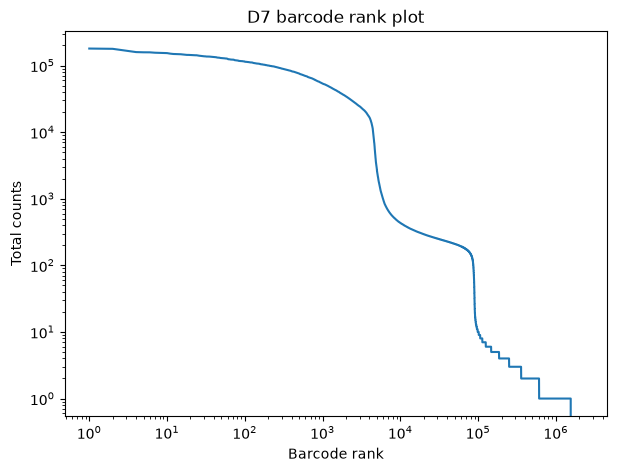

In [73]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

plt.plot(
    np.arange(1, len(counts_sorted) + 1),
    counts_sorted
)

plt.xscale("log")
plt.yscale("log")

plt.xlabel("Barcode rank")
plt.ylabel("Total counts")
plt.title("D7 barcode rank plot")

plt.show()

In [1]:
candidate_d7 = adata_d7[
    adata_d7.obs["total_counts"] >= 1000
].copy()

print(candidate_d7)

NameError: name 'adata_d7' is not defined

In [2]:
print(adata_d7)

NameError: name 'adata_d7' is not defined

In [11]:
jupyter lab --version


SyntaxError: invalid syntax (189726742.py, line 1)

In [10]:
jupyter notebook --version

SyntaxError: invalid syntax (1474598263.py, line 1)

In [12]:
import sys
import IPython
try:
    import jupyterlab
    print("JupyterLab:", jupyterlab.__version__)

SyntaxError: incomplete input (1500038766.py, line 5)

In [13]:
import sys
import IPython

print("Python:", sys.version.split()[0])
print("IPython:", IPython.__version__)

try:
    import jupyterlab
    print("JupyterLab:", jupyterlab.__version__)
except ImportError:
    pass

try:
    import notebook
    print("Notebook:", notebook.__version__)
except ImportError:
    pass

Python: 3.11.16
IPython: 9.17.1
JupyterLab: 4.6.4
